# 05 — Classificação: como são os cartórios vagos, e quantos vão passar a ser obrigados?

**Para que serve este notebook.** Dois problemas de **classificação** (dizer "sim" ou "não" para cada serventia, com uma probabilidade), ambos com a resposta real nos dados:
- **(a) Vacância:** dá para reconhecer as serventias **vagas** (com interino) pela receita, pelos empregados, pelas atribuições e pela região? O fim da delegação é o risco que o seguro cobre (D-025).
- **(b) Subida de classe:** uma serventia abaixo de R$ 300 mil por semestre vai **passar do limite no ano seguinte**? Quem passa sai da Classe 1 e, se for provida, fica **obrigada** pelo Prov. 227: é o crescimento do mercado. A entrega é a **contagem esperada de subidas em 2026 e 2027, com faixa** (insumo do notebook 07).

Os métodos foram escolhidos pelos testes **T4** (vacância) e **T3** (subida) em `docs/qa/analises/testes_metodos.md`; aqui usamos o vencedor, a mesma referência e a mesma validação, e conferimos se o resultado bate com o do teste. Este notebook **não muda** nenhum dos 10 números do `docs/ESTADO_ATUAL.md`: tudo o que olha para 2026–27 é **projeção**.

**Termos usados** (explicados onde aparecem pela primeira vez): probabilidade prevista, referência, regressão logística, razão de chances, floresta aleatória, validação cruzada estratificada, validação temporal, matriz de confusão, limiar, precisão, recall, AUC, AP, Brier, importância por permutação, vazamento, recalibração, origem móvel.

**Dados:** banco do pipeline (carga de 19/10/2026: cadastro, arrecadação e empregados do CNJ/Justiça Aberta; população e regiões do IBGE), cenário **base**, regra de classe **v2**. Parâmetros em `config/analise.yaml` (`classificacao`), copiados dos testes. Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter
from sklearn.metrics import roc_curve

from src.analise import classificacao as cl, config, dados, enquadramento, graficos as g
from src.notebooks import conectar

g.estilo()
cfg = config()["classificacao"]
semente = config()["semente"]
con = conectar()
sv = dados.serventias(con)
serie = dados.serie_arrecadacao(con)
limite = enquadramento.limites_classe()[0]
print(f"{g.num(len(sv))} serventias ativas; limite da Classe 1 (regra v2): {g.reais(limite)} por semestre; semente {semente}.")

2.525 serventias ativas; limite da Classe 1 (regra v2): R$ 300,0 mil por semestre; semente 20261022.


## Como medir um classificador (vale para as duas partes)

Um classificador dá, para cada serventia, uma **probabilidade** de "sim" (por exemplo, 0,8 = 80% de chance de ser vaga). As medidas:

- **Matriz de confusão:** escolhido um **limiar** (aqui, 0,5), quem passa dele é chamado de "sim". Contamos os **verdadeiros positivos** (VP: chamados de "sim" e são), os **falsos positivos** (FP: chamados de "sim" e não são), os **falsos negativos** (FN: "sim" que o modelo não achou) e os **verdadeiros negativos** (VN).
- **Precisão** = VP ÷ (VP + FP): dos chamados de "sim", quantos são. **Recall** = VP ÷ (VP + FN): dos "sim" de verdade, quantos foram achados. Exemplo: 100 vagas, o modelo chama 80 serventias de vagas e acerta 60: precisão = 60 ÷ 80 = 75%; recall = 60 ÷ 100 = 60%.
- **AUC:** pegue um "sim" e um "não" ao acaso; a AUC é a chance de o "sim" ter a probabilidade maior. 0,5 = chute; 1 = perfeito. Não depende do limiar.
- **AP** (precisão média): como a AUC, mas focada nos "sim"; útil quando eles são raros. A referência é a própria proporção de "sim".
- **Brier** = média de (probabilidade − resposta)², com resposta 1 ou 0. Exemplo: prever 0,9 e acontecer dá (0,9 − 1)² = 0,01; prever 0,9 e não acontecer dá 0,81. Menor é melhor. Mede se a **probabilidade** está certa, não só a ordem.
- **Referência** (o "chute"): dar a todos a mesma probabilidade, a proporção de "sim" no treino. Tem AUC 0,5 por construção. Um modelo só vale se for melhor que ela.

**Os modelos.**
- **Regressão logística:** soma as variáveis com pesos e passa o resultado por uma curva em "S" que fica entre 0 e 1. Com as variáveis **padronizadas** (em desvios padrão), o peso diz quanto 1 desvio a mais muda o log da chance; **e^peso** é a **razão de chances**: 2 = a chance ("sim" ÷ "não") dobra. É a versão "explicável".
- **Floresta aleatória:** 500 árvores de decisão, cada uma treinada numa reamostragem das serventias e olhando um sorteio das variáveis; a probabilidade é a média das árvores. Pega relações não lineares e combinações, mas não dá um peso por variável.
- **Importância por permutação:** embaralha uma variável (troca os valores entre as serventias, quebrando a ligação com a resposta) e mede quanto a métrica piora em dados que o modelo **não viu**. Se piora muito, o modelo dependia dela. As 13 colunas de região são embaralhadas juntas, como uma variável só.

---
# Parte (a) — Vacância (teste T4)

## a1. A pergunta e os dados

**A pergunta.** Pela receita, pelos empregados, pelas atribuições, pela população do município e pela região, dá para reconhecer as serventias vagas?

**Os dados.** As serventias **providas ou vagas** (as 41 "outras" ficam fora, como no T4) com receita de referência de 2025 e CLT informados. Variáveis, as mesmas do T4: log da receita, log(1 + CLT), número de atribuições, as 6 atribuições (0/1), log da população do município e a região intermediária (13 colunas 0/1).

**Vazamento declarado.** Vazamento é usar uma variável que só existe, ou só tem aquele valor, **por causa** da resposta.
- **Descartadas por vazamento:** a data da situação (muda quando a serventia vaga), o motivo do universo (`interinidade`), o peso do universo, o déficit e as serventias com déficit (todos zerados nas vagas por regra do modelo) e a situação jurídica, que é a própria resposta.
- **Descartadas por serem cópia de outra variável:** o passivo e o passivo médio por vínculo (contas sobre o CLT e o salário do município) e a classe (a receita em faixas).
- **Vazamento que fica, e é declarado:** a **receita e os empregados** de uma serventia vaga são medidos **já sob o interino**. Um interino tende a manter a serventia enxuta e tem teto de remuneração, então parte do sinal vem da própria vacância. Por isso o resultado é lido como **associação** ("cartórios vagos costumam ser assim"), **não como previsão** de quem vai vagar. A seção a5 mede quanto o modelo perde sem essas duas variáveis.

In [2]:
x_vag, y_vag = cl.base_vacancia(sv)
print(f"{g.num(len(x_vag))} serventias (providas ou vagas, com receita e CLT); vagas: {g.num(y_vag.sum())} "
      f"({g.pct(y_vag.mean())}). T4: 2.406 serventias, 32,4% vagas.")

2.406 serventias (providas ou vagas, com receita e CLT); vagas: 780 (32,4%). T4: 2.406 serventias, 32,4% vagas.


## a2. O método e a validação

**Validação cruzada estratificada 5 × 3** (a mesma do T4): as serventias são divididas em 5 partes com a mesma % de vagas ("estratificada"); cada parte é prevista por um modelo treinado nas outras 4, e cada serventia é prevista uma vez, sem ter sido vista. Isso é repetido 3 vezes, com sorteios diferentes, e as métricas são a média das 15 rodadas. **Indicador que decide** (fixado no T4): a **AUC**.

Por que a floresta: ganhou o T4 (AUC 0,886, contra 0,870 do gradient boosting, 0,848 da logística e 0,500 da referência). A logística entra para explicar os pesos.

In [3]:
tab_vag, oof_vag = cl.validacao_cruzada(x_vag, y_vag)
t4 = cl.resultado_do_teste("T4_vacancia")
tab_vag["AUC no T4"] = [t4.loc["referência: proporção de vagas" if m == "referência" else m, "AUC"] for m in tab_vag.index]
tab_vag["Brier no T4"] = [t4.loc["referência: proporção de vagas" if m == "referência" else m, "Brier"] for m in tab_vag.index]
display(g.tabela(tab_vag.reset_index(names="modelo"),
                 {c: "pct" if c in ("precisao", "recall") else "num2" for c in tab_vag.columns})
        .rename(columns={"precisao": "precisão"}))
print(f"Floresta: AUC {g.num(tab_vag.loc['Floresta aleatória', 'AUC'], 3)} (T4: {g.num(t4.loc['Floresta aleatória', 'AUC'], 3)}); "
      f"logística {g.num(tab_vag.loc['Regressão logística', 'AUC'], 3)} (T4: {g.num(t4.loc['Regressão logística', 'AUC'], 3)}).")

,modelo,AUC,AP,Brier,precisão,recall,AUC no T4,Brier no T4
0,referência,"0,50","0,32","0,22",—,"0,0%","0,50","0,22"
1,Regressão logística,"0,85","0,77","0,13","78,7%","62,0%","0,85","0,13"
2,Floresta aleatória,"0,88","0,80","0,12","78,0%","68,0%","0,89","0,12"


Floresta: AUC 0,884 (T4: 0,886); logística 0,849 (T4: 0,848).


**Como ler.** Uma linha por modelo, com a média das 15 rodadas; as duas últimas colunas trazem o resultado do T4 para comparar. Precisão e recall usam o limiar 0,5 (a referência nunca passa dele, por isso não tem precisão e tem recall 0).

**O que encontramos.** A floresta separa bem vagas de providas: **AUC 0,88**, contra 0,85 da logística e 0,50 da referência. O Brier cai de 0,22 (referência) para 0,12. **O resultado bate com o T4** (AUC 0,886 e 0,848): a diferença na terceira casa vem da semente (o T4 usou 42; aqui, a de `config/analise.yaml`).

**Limitações.** A validação cruzada mede o acerto em serventias de MG que o modelo não viu, mas todas da mesma data; não diz se o modelo valeria em outro estado ou em outro ano.

Floresta, 1ª repetição, cada serventia prevista fora da dobra, limiar 0.5: VP 527, FP 153, FN 253, VN 1473; precisão 77,5%, recall 67,6%.
  vagas achadas (VP): 527; receita mediana R$ 46,2 mil; acima do limite da Classe 1: 0,0%.
  vagas não achadas (FN): 253; receita mediana R$ 365,4 mil; acima do limite da Classe 1: 59,3%.
  providas chamadas de vagas (FP): 153; receita mediana R$ 104,6 mil; acima do limite da Classe 1: 0,0%.


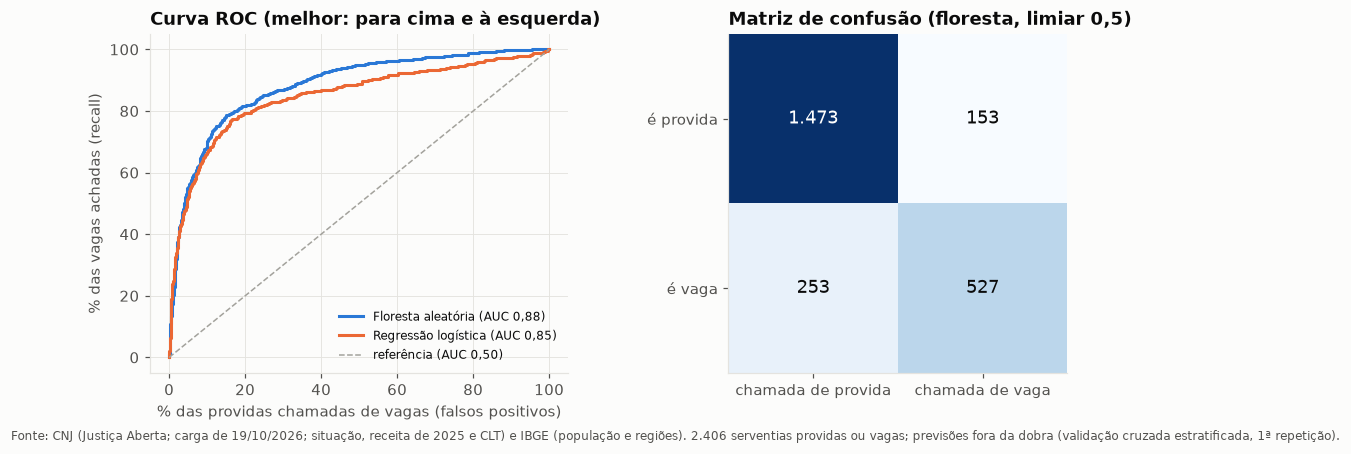

In [4]:
m = cl.metricas(oof_vag["Floresta aleatória"], y_vag.to_numpy())
print(f"Floresta, 1ª repetição, cada serventia prevista fora da dobra, limiar {cfg['limiar']}: "
      f"VP {m['vp']}, FP {m['fp']}, FN {m['fn']}, VN {m['vn']}; precisão {g.pct(m['precisao'])}, recall {g.pct(m['recall'])}.")
receita_vag = sv.set_index("cns").loc[x_vag.index, "receita_ref"]
chamada = oof_vag["Floresta aleatória"] >= cfg["limiar"]
for rotulo, msk in [("vagas achadas (VP)", (y_vag == 1).to_numpy() & chamada),
                    ("vagas não achadas (FN)", (y_vag == 1).to_numpy() & ~chamada),
                    ("providas chamadas de vagas (FP)", (y_vag == 0).to_numpy() & chamada)]:
    print(f"  {rotulo}: {g.num(msk.sum())}; receita mediana {g.reais(receita_vag[msk].median())}; "
          f"acima do limite da Classe 1: {g.pct((receita_vag[msk] > limite).mean())}.")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
fig.subplots_adjust(wspace=0.35)
for nome, cor in [("Floresta aleatória", g.CORES[0]), ("Regressão logística", g.CORES[1])]:
    fpr, tpr, _ = roc_curve(y_vag, oof_vag[nome])
    a1.plot(100 * fpr, 100 * tpr, color=cor, label=f"{nome} (AUC {g.num(cl.metricas(oof_vag[nome], y_vag)['AUC'], 2)})")
a1.plot([0, 100], [0, 100], color=g.CINZA, linestyle="--", linewidth=1, label="referência (AUC 0,50)")
a1.set_xlabel("% das providas chamadas de vagas (falsos positivos)")
a1.set_ylabel("% das vagas achadas (recall)")
a1.set_title("Curva ROC (melhor: para cima e à esquerda)")
a1.legend(fontsize=8, loc="lower right")
conf = np.array([[m["vn"], m["fp"]], [m["fn"], m["vp"]]])
a2.imshow(conf, cmap="Blues")
for (i, j), v in np.ndenumerate(conf):
    a2.text(j, i, g.num(v), ha="center", va="center", fontsize=12, color="white" if v > conf.max() / 2 else g.TEXTO)
a2.set_xticks([0, 1], ["chamada de provida", "chamada de vaga"])
a2.set_yticks([0, 1], ["é provida", "é vaga"])
a2.grid(False)
a2.set_title(f"Matriz de confusão (floresta, limiar {g.num(cfg['limiar'], 1)})")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta; carga de 19/10/2026; situação, receita de 2025 e CLT) e IBGE (população e regiões). "
            f"{g.num(len(x_vag))} serventias providas ou vagas; previsões fora da dobra (validação cruzada estratificada, 1ª repetição).")
g.salvar(fig, "05a_vacancia_roc_matriz_confusao")
plt.show()

**Como ler.** À esquerda, a **curva ROC**: cada ponto é um limiar diferente; o eixo x é a % de providas chamadas de vagas por engano, e o y a % de vagas achadas. A diagonal é o chute. À direita, as quatro contagens com o limiar 0,5.

**O que encontramos.** Com o limiar 0,5, a floresta acha cerca de **2 em cada 3 vagas** (recall ≈ 68%) e, das que chama de vagas, acerta cerca de **78%**. As vagas que ela **não** acha são as maiores: receita mediana de cerca de R$ 365 mil, e 59% delas acima do limite da Classe 1, contra R$ 46 mil e nenhuma acima do limite entre as vagas achadas. São as "vagas grandes" do notebook 04 (grupo 5), parecidas com as providas. Os falsos positivos são o contrário: providas pequenas (mediana de cerca de R$ 105 mil), com cara de vaga.

**Limitações.** O limiar 0,5 é uma escolha (`fonte: suposição`); com um limiar menor, o recall sobe e a precisão cai (a curva ROC mostra essa troca). A matriz é de uma repetição só da validação cruzada.

## a3. O que mais pesa: importância por permutação e pesos da logística

**O método.** Importância por permutação da floresta, medida pela queda da AUC em cada dobra de uma validação cruzada de 5 partes, com cada variável embaralhada 10 vezes. Em seguida, os pesos da logística (ajustada em todas as serventias, variáveis padronizadas).

,variavel,queda média da AUC,desvio padrão
0,log da receita,"0,105","0,017"
1,log da população,"0,021","0,006"
2,Registro civil (RCPN),"0,018","0,006"
3,nº de atribuições,"0,016","0,005"
4,log(1 + CLT),"0,009","0,005"
5,Notas,"0,008","0,004"
6,região (13 colunas),"0,003","0,003"
7,Protesto,"0,002","0,002"
8,Títulos e documentos (RTD),"0,001","0,001"
9,Pessoas jurídicas (RCPJ),"0,000","0,001"


,variavel,peso,razão de chances (1 desvio a mais),1 desvio padrão =
0,log_receita,"-1,38","0,25","1,70"
1,ri,"0,70","2,01","0,33"
2,rcpn,"0,52","1,68","0,50"
3,log_pop,"0,51","1,67","1,34"
4,notas,"0,44","1,55","0,47"
5,rcpj,"-0,22","0,80","0,31"
6,protesto,"-0,21","0,81","0,33"
7,regiao_Pouso Alegre,"-0,16","0,85","0,28"
8,n_atribuicoes,"0,15","1,16","0,61"
9,regiao_Uberaba,"0,13","1,14","0,18"


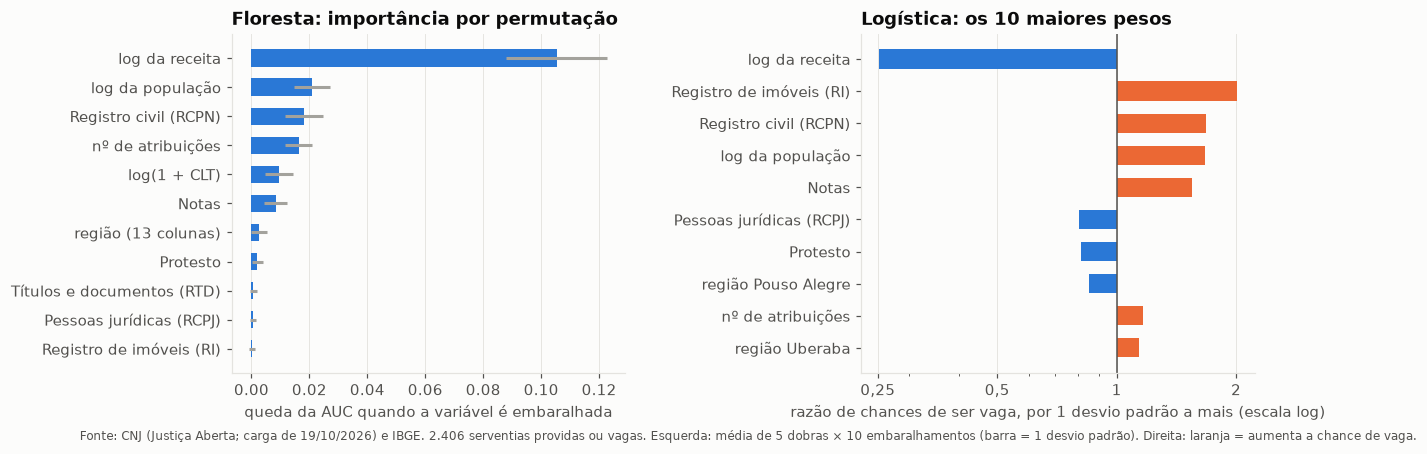

In [5]:
regioes = [c for c in x_vag if c.startswith("regiao_")]
grupos_vag = {"log da receita": ["log_receita"], "log(1 + CLT)": ["log_clt"], "nº de atribuições": ["n_atribuicoes"],
              **{dados.NOMES_ATRIBUICOES[a]: [a] for a in dados.ATRIBUICOES}, "log da população": ["log_pop"],
              "região (13 colunas)": regioes}
imp_vag = cl.importancia_permutacao(cl.modelos()["Floresta aleatória"], x_vag, y_vag, grupos_vag)
coef_vag = cl.coeficientes_logistica(x_vag, y_vag)
display(g.tabela(imp_vag, {"perda_media": "num3", "perda_dp": "num3"})
        .rename(columns={"perda_media": "queda média da AUC", "perda_dp": "desvio padrão"}))
display(g.tabela(coef_vag.head(10), {"peso": "num2", "razao_de_chances": "num2", "desvio_padrao": "num2"})
        .rename(columns={"razao_de_chances": "razão de chances (1 desvio a mais)", "desvio_padrao": "1 desvio padrão ="}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
fig.subplots_adjust(wspace=0.6)
yi = np.arange(len(imp_vag))
a1.barh(yi, imp_vag.perda_media, xerr=imp_vag.perda_dp, color=g.AZUL["medio"], height=0.6, ecolor=g.CINZA)
a1.set_yticks(yi, imp_vag.variavel)
a1.invert_yaxis()
a1.set_xlabel("queda da AUC quando a variável é embaralhada")
a1.grid(axis="y", visible=False)
a1.set_title("Floresta: importância por permutação")
top = coef_vag.head(10).iloc[::-1]
nomes_coef = {**{a: dados.NOMES_ATRIBUICOES[a] for a in dados.ATRIBUICOES}, "log_receita": "log da receita",
              "log_clt": "log(1 + CLT)", "log_pop": "log da população", "n_atribuicoes": "nº de atribuições"}
a2.barh(np.arange(len(top)), top.razao_de_chances - 1, left=1, height=0.6,
        color=[g.CORES[1] if v > 1 else g.CORES[0] for v in top.razao_de_chances])
a2.axvline(1, color=g.TEXTO_2, linewidth=1)
a2.set_yticks(np.arange(len(top)), [nomes_coef.get(v, v.replace("regiao_", "região ")) for v in top.variavel])
a2.set_xscale("log")
a2.set_xticks([0.25, 0.5, 1, 2], ["0,25", "0,5", "1", "2"])
a2.xaxis.set_minor_formatter(NullFormatter())
a2.set_xlabel("razão de chances de ser vaga, por 1 desvio padrão a mais (escala log)")
a2.grid(axis="y", visible=False)
a2.set_title("Logística: os 10 maiores pesos")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta; carga de 19/10/2026) e IBGE. {g.num(len(x_vag))} serventias providas ou vagas. "
            "Esquerda: média de 5 dobras × 10 embaralhamentos (barra = 1 desvio padrão). Direita: laranja = aumenta a chance de vaga.")
g.salvar(fig, "05a_vacancia_importancia")
plt.show()

**Como ler.** À esquerda, quanto a AUC cai quando cada variável é embaralhada (maior = mais importante). À direita, a razão de chances da logística: acima de 1 (laranja), a variável **aumenta** a chance de a serventia ser vaga; abaixo de 1 (azul), diminui.

**O que encontramos.**
- A **receita** é, de longe, a variável que mais pesa: embaralhá-la derruba a AUC em cerca de 0,1. Na logística, cada desvio padrão a mais de receita (um fator de cerca de 5 vezes) multiplica a chance de ser vaga por **0,25**: as vagas são as serventias pequenas.
- Depois vêm a **população do município**, o **RCPN** e o **número de atribuições**. Com a receita fixa, ter RCPN ou RI, ou estar num município mais populoso, **aumenta** a chance de vaga.
- O **CLT** pesa pouco **depois** que a receita entra (as duas andam juntas, Spearman 0,83 no notebook 02), e a região quase nada.

**Cuidado com a leitura dos pesos.** Na logística, cada peso vale "com as outras variáveis fixas". O sinal positivo do RI, por exemplo, não diz que cartórios de RI vagam mais; diz que, **entre cartórios com a mesma receita**, os de RI estão mais vezes vagos (ou seja, um RI com receita baixa é provavelmente um RI sob interino). Com RTD e RCPJ quase sempre juntos (notebook 03), os pesos dos dois se dividem.

**Limitações.** A importância por permutação subestima variáveis que andam juntas (embaralhar uma deixa a outra carregando o sinal): o CLT parece pouco importante porque a receita conta quase a mesma história. Nenhum desses pesos é causa.

## a4. Quanto do sinal vem do vazamento?

**O método.** A mesma validação, sem a receita e sem o CLT (as duas variáveis medidas sob o interino). O que sobra (atribuições, população e região) não depende de quem está à frente do cartório.

In [6]:
x_sem = x_vag.drop(columns=["log_receita", "log_clt"])
tab_sem, _ = cl.validacao_cruzada(x_sem, y_vag)
display(g.tabela(pd.DataFrame({"AUC com receita e CLT": tab_vag.AUC, "AUC sem receita e CLT": tab_sem.AUC,
                               "Brier com": tab_vag.Brier, "Brier sem": tab_sem.Brier}).reset_index(names="modelo"),
                 {"AUC com receita e CLT": "num3", "AUC sem receita e CLT": "num3", "Brier com": "num3", "Brier sem": "num3"}))

,modelo,AUC com receita e CLT,AUC sem receita e CLT,Brier com,Brier sem
0,referência,"0,500","0,500","0,219","0,219"
1,Regressão logística,"0,849","0,792","0,134","0,167"
2,Floresta aleatória,"0,884","0,817","0,123","0,159"


**O que encontramos.** Sem a receita e o CLT, a AUC da floresta cai de 0,88 para **cerca de 0,82**: ainda bem acima do chute. Ou seja, boa parte da diferença entre vagas e providas está no **tipo** de cartório (atribuições e tamanho do município), que não depende do interino. A outra parte (de 0,82 para 0,88) pode ser vazamento ou pode ser real; os dados não deixam separar.

## a5. O que significa para o seguro, e limitações

**O que significa para o Prov. 227.**
- As vagas são, sobretudo, **cartórios pequenos de registro civil em distritos e municípios pequenos**: o mesmo perfil do grupo 1 do notebook 04, quase todo Classe 1. Para a seguradora, isso é uma boa notícia: o risco de vacância **observado** se concentra fora do universo de obrigadas.
- Mas o modelo erra justamente nas **vagas grandes** (grupo 5 do notebook 04): elas se parecem com providas. Uma serventia grande pode vagar, e quando vaga, o contrato precisa ser encerrado ou transferido.

**Limitações.**
- É **associação**, não previsão: o modelo descreve como são as vagas **hoje**, não diz quais providas vão vagar. Para prever vacância, seria preciso a história da situação de cada serventia (quando vagou), que não está no banco; a chance de a delegação terminar no ano é uma lacuna já conhecida (D-025, notebook 09).
- O vazamento da receita e do CLT foi medido (seção a4), mas não eliminado.
- A situação é a do cadastro do CNJ na coleta (carga de 19/10/2026).

---
# Parte (b) — Subida de classe (teste T3)

## b1. A pergunta e os dados

**A pergunta.** Uma serventia com receita até R$ 300 mil por semestre num ano vai passar do limite no ano seguinte?

**Os dados** (os mesmos do T3). Para cada ano t de 2011 a 2025 e cada serventia ativa com receita até o limite no ano t − 1 (e com receita nos anos t − 1 e t − 2), um **caso**. A receita de um ano é a **média dos semestres com valor > 0** (a regra da receita de referência, D-010, aplicada ano a ano). Resposta: 1 se a receita do ano t passa do limite.

**Variáveis, só do passado** (nada do ano t, para não haver vazamento): log da receita em t − 1 e t − 2, o crescimento de t − 2 para t − 1 e de t − 3 para t − 2, a distância ao limite (log de limite ÷ receita), o log do maior semestre de t − 1, as atribuições, o número de atribuições e o log da população. O limite é o mesmo em todos os anos (R$ 300 mil, regra v2), como no T3.

**Validação temporal:** treina com os anos até **2023** e testa em **2024 e 2025**, que o modelo não viu. Misturar anos seria trapaça: o modelo aprenderia com o futuro. **Indicador que decide** (fixado no T3): o **Brier**, porque a contagem de subidas é a **soma** das probabilidades, então a probabilidade precisa estar certa, e não só a ordem.

In [7]:
media, maximo = cl.receita_anual(serie)
info = cl.info_serventias(sv)
sc = cfg["subida"]
painel = cl.painel_subida(media, maximo, info, range(sc["primeiro_ano"], max(sc["anos_teste"]) + 1), limite)
treino = painel[painel.ano <= sc["ano_treino_fim"]]
teste = painel[painel.ano.isin(sc["anos_teste"])]
print(f"Casos: {g.num(len(painel))} ({g.num(len(treino))} de treino, até {sc['ano_treino_fim']}; {g.num(len(teste))} de teste, "
      f"{sc['anos_teste'][0]}–{sc['anos_teste'][-1]}). Subidas no teste: {g.num(teste.y.sum())} ({g.pct(teste.y.mean())}). "
      f"T3: 24.416 e 2.692 casos, 10,9% de subidas.")
por_ano = painel.groupby("ano").y.agg(casos="size", subidas="sum", taxa="mean").reset_index()
display(g.tabela(por_ano, {"casos": "int", "subidas": "int", "taxa": "pct"}).set_index("ano").T)

Casos: 27.108 (24.416 de treino, até 2023; 2.692 de teste, 2024–2025). Subidas no teste: 294 (10,9%). T3: 24.416 e 2.692 casos, 10,9% de subidas.


ano,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
casos,2.122,2.050,2.034,1.997,1.990,1.963,1.927,1.880,1.862,1.781,1.753,1.579,1.478,1.403,1.289
subidas,74,54,72,53,53,59,66,48,85,64,179,123,96,124,170
taxa,"3,5%","2,6%","3,5%","2,7%","2,7%","3,0%","3,4%","2,6%","4,6%","3,6%","10,2%","7,8%","6,5%","8,8%","13,2%"


**Como ler.** Para cada ano, quantas serventias estavam abaixo do limite no ano anterior (casos), quantas passaram e a taxa.

**O que encontramos.** A taxa de subida ficou entre 2,6% e 4,6% ao ano até 2020 e **saltou a partir de 2021** (de 6,5% a 13,2%): com a inflação e o crescimento da arrecadação, mais cartórios cruzam um limite fixo em reais. Isso é o que torna a previsão difícil: o passado recente não se parece com o passado distante.

## b2. Os modelos contra a referência, e contra o T3

**O método.** As referências e os modelos do T3, treinados até 2023:
- **referência: taxa histórica** = a taxa média de subida de 2019 a 2023, para todas as serventias;
- **regressão logística** e **floresta aleatória** (vencedora do T3: Brier 0,068, contra 0,069 da logística e 0,099 da taxa histórica).

In [8]:
t3 = cl.resultado_do_teste("T3_subida_de_classe")
x_tr, y_tr = treino[cl.VARIAVEIS_SUBIDA], treino.y
x_te, y_te = teste[cl.VARIAVEIS_SUBIDA], teste.y.to_numpy()
taxa_hist = treino[treino.ano >= sc["taxa_desde"]].y.mean()
mods = cl.modelos()
floresta_t = mods["Floresta aleatória"].fit(x_tr, y_tr)
prob = {"referência: taxa histórica": np.full(len(teste), taxa_hist),
        "Regressão logística": mods["Regressão logística"].fit(x_tr, y_tr).predict_proba(x_te)[:, 1],
        "Floresta aleatória": floresta_t.predict_proba(x_te)[:, 1]}
res_b = pd.DataFrame({k: cl.metricas(p, y_te) for k, p in prob.items()}).T
nome_t3 = {"referência: taxa histórica": "referência: taxa histórica (2019–2023)"}
res_b["Brier no T3"] = [t3.loc[nome_t3.get(k, k), "Brier"] for k in res_b.index]
res_b["previstas no T3"] = [t3.loc[nome_t3.get(k, k), "previstas"] for k in res_b.index]
display(g.tabela(res_b[["Brier", "AUC", "AP", "precisao", "recall", "previstos", "reais", "Brier no T3", "previstas no T3"]]
                 .reset_index(names="modelo"),
                 {"Brier": "num3", "AUC": "num2", "AP": "num2", "precisao": "pct", "recall": "pct", "previstos": "num1",
                  "reais": "int", "Brier no T3": "num3", "previstas no T3": "num1"})
        .rename(columns={"precisao": "precisão", "previstos": "subidas previstas", "reais": "subidas reais"}))
mf = res_b.loc["Floresta aleatória"]
print(f"Taxa histórica (2019–2023): {g.pct(taxa_hist)}. Matriz de confusão da floresta no teste (limiar {cfg['limiar']}): "
      f"VP {int(mf.vp)}, FP {int(mf.fp)}, FN {int(mf.fn)}, VN {int(mf.vn)}.")

,modelo,Brier,AUC,AP,precisão,recall,subidas previstas,subidas reais,Brier no T3,previstas no T3
0,referência: taxa histórica,"0,099","0,50","0,11",—,"0,0%","174,2",294,"0,099","174,2"
1,Regressão logística,"0,069","0,87","0,55","71,1%","20,1%","194,6",294,"0,069","194,6"
2,Floresta aleatória,"0,068","0,88","0,55","66,1%","37,8%","217,7",294,"0,068","218,0"


Taxa histórica (2019–2023): 6,5%. Matriz de confusão da floresta no teste (limiar 0.5): VP 111, FP 57, FN 183, VN 2341.


**Como ler.** "Subidas previstas" é a soma das probabilidades no teste; "reais", quantas subiram de fato. Precisão e recall com o limiar 0,5.

**O que encontramos.**
- A floresta tem o menor Brier (**0,068**, contra 0,099 da taxa histórica) e ordena bem quem tende a subir (**AUC 0,88**). **Bate com o T3**: mesmo Brier e 218 subidas previstas, praticamente iguais às do teste.
- Mas **todos subestimam quantos sobem**: a floresta prevê **218** e houve **294** (−26%). Com o limiar 0,5, ela acha só 38% das subidas (111 de 294, com 57 alarmes falsos): a maioria das serventias que sobem tem probabilidade prevista abaixo de 50%. Para contar subidas, isso não é problema, porque a contagem soma as probabilidades, sem limiar.

**Limitações.** O teste tem só dois anos (2024 e 2025) e 294 subidas; uma diferença de Brier na terceira casa entre modelos não é conclusiva.

## b3. A recalibração com 2022–23

**A pergunta.** Dá para corrigir a subestimação ajustando as probabilidades com os anos mais recentes, como pede o plano?

**O método: recalibração de Platt.** Uma segunda regressão logística, com uma só variável, o **logito** da probabilidade da floresta (logito = log(p ÷ (1 − p))), aprende a "esticar" ou "deslocar" as probabilidades para que batam com o que aconteceu. Exemplo: se, nos anos de recalibração, as serventias com probabilidade de 10% subiram 15% das vezes, a recalibração passa a transformar 10% em cerca de 15%.

Para não usar o futuro, a recalibração é ajustada em **2022–23** com as previsões de uma floresta **treinada só até 2021** (anos que ela não viu); depois, a correção aprendida é aplicada às previsões da floresta treinada até 2023 para 2024–25.

In [9]:
r_teste = cl.prever_subidas(painel, teste)
m_rec = cl.metricas(r_teste["p_recal"], y_te)
efeito = pd.DataFrame({"sem recalibração": cl.metricas(r_teste["p"], y_te), "recalibrada (2022–23)": m_rec}).T
display(g.tabela(efeito[["Brier", "AUC", "previstos", "reais"]].reset_index(names="floresta"),
                 {"Brier": "num3", "AUC": "num2", "previstos": "num1", "reais": "int"})
        .rename(columns={"previstos": "subidas previstas", "reais": "subidas reais"}))
print(f"Brier com 4 casas: {g.num(efeito.Brier.iloc[0], 4)} → {g.num(efeito.Brier.iloc[1], 4)}. Erro da contagem: "
      f"{g.pct(efeito.previstos.iloc[0] / efeito.reais.iloc[0] - 1)} → {g.pct(efeito.previstos.iloc[1] / efeito.reais.iloc[1] - 1)}.")

,floresta,Brier,AUC,subidas previstas,subidas reais
0,sem recalibração,"0,068","0,88","217,7",294
1,recalibrada (2022–23),"0,068","0,88","249,3",294


Brier com 4 casas: 0,0680 → 0,0676. Erro da contagem: -26,0% → -15,2%.


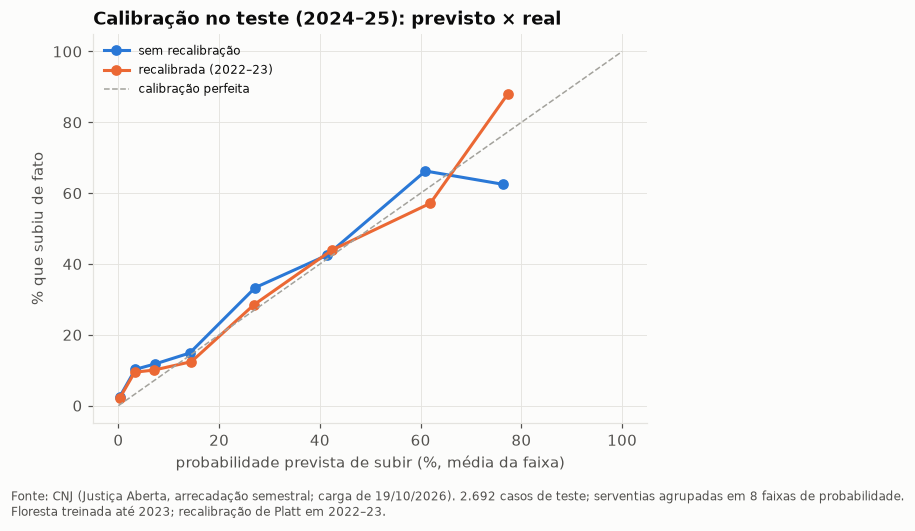

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
cortes = np.array([0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0])
for nome, p, cor in [("sem recalibração", r_teste["p"], g.CORES[0]), ("recalibrada (2022–23)", r_teste["p_recal"], g.CORES[1])]:
    faixa = pd.cut(p, cortes, include_lowest=True)
    t = pd.DataFrame({"p": p, "y": y_te, "f": faixa}).groupby("f", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax.plot(100 * t.p, 100 * t.y, marker="o", color=cor, label=nome)
ax.plot([0, 100], [0, 100], color=g.CINZA, linestyle="--", linewidth=1, label="calibração perfeita")
ax.set_xlabel("probabilidade prevista de subir (%, média da faixa)")
ax.set_ylabel("% que subiu de fato")
ax.legend(fontsize=8)
ax.set_title("Calibração no teste (2024–25): previsto × real")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta, arrecadação semestral; carga de 19/10/2026). {g.num(len(teste))} casos de teste; "
            "serventias agrupadas em 8 faixas de probabilidade.\nFloresta treinada até 2023; recalibração de Platt em 2022–23.")
g.salvar(fig, "05b_subida_calibracao_teste")
plt.show()

**Como ler.** Cada ponto é uma faixa de probabilidade prevista: no eixo x, a média prevista; no y, a % que subiu de fato. Na linha tracejada, previsto = real. Pontos **acima** da linha = o modelo **subestima**.

**O que encontramos.** A subestimação da floresta está nas **faixas de probabilidade baixa e média** (até cerca de 30%), onde fica a maioria dos casos: ali os pontos azuis ficam acima da linha. A recalibração sobe essas probabilidades e aproxima os pontos da linha; a contagem prevista vai de **218 para 249** (erro de −26% para −15%) e o Brier melhora um pouco (0,0680 → 0,0676). A AUC não muda, porque a recalibração mantém a ordem das serventias. **Ainda falta**: 249 contra 294 reais. As duas faixas mais altas têm poucos casos e oscilam para os dois lados.

**Limitações.** A recalibração aprende com só dois anos (3.057 casos e 219 subidas em 2022–23): ela supõe que o "erro" do modelo nesses anos se repete nos anos seguintes. A seção b4 testa essa suposição.

## b4. A recalibração ajuda sempre? Teste no passado com origem móvel

**A pergunta.** O ganho da recalibração em 2024–25 se repete em outros anos, ou foi sorte?

**O método: origem móvel.** Repetimos o teste para cada par de anos de 2015–16 a 2024–25: treina com os anos anteriores, recalibra com os dois anos imediatamente antes e prevê o par, **sempre sem olhar o futuro**. Comparamos as subidas previstas, com e sem recalibração, com as reais. A razão "reais ÷ previstas" de cada janela mostra o tamanho do erro (1 = acerto; 1,2 = previu 20% a menos).

,anos,casos,reais,previstas_modelo,previstas_recalibradas,razao_modelo,razao_recalibrada,brier_modelo,brier_recalibrado
0,2015–2016,3.953,112,"175,8","167,4","0,64","0,67","0,021","0,020"
1,2016–2017,3.890,125,"168,8","105,1","0,74","1,19","0,021","0,021"
2,2017–2018,3.807,114,"157,9","99,4","0,72","1,15","0,020","0,020"
3,2018–2019,3.742,133,"158,0","117,9","0,84","1,13","0,024","0,023"
4,2019–2020,3.643,149,"160,5","115,5","0,93","1,29","0,026","0,027"
5,2020–2021,3.534,243,"160,7","135,1","1,51","1,80","0,042","0,044"
6,2021–2022,3.332,302,"153,7","143,2","1,96","2,11","0,054","0,056"
7,2022–2023,3.057,219,"187,2","284,3","1,17","0,77","0,044","0,044"
8,2023–2024,2.881,220,"213,9","383,5","1,03","0,57","0,049","0,063"
9,2024–2025,2.692,294,"217,7","249,3","1,35","1,18","0,068","0,068"


Erro absoluto médio da contagem nas 10 janelas: sem recalibração 53,3; recalibrada 67,9. Janelas em que a recalibração melhorou o Brier: 4 de 10.


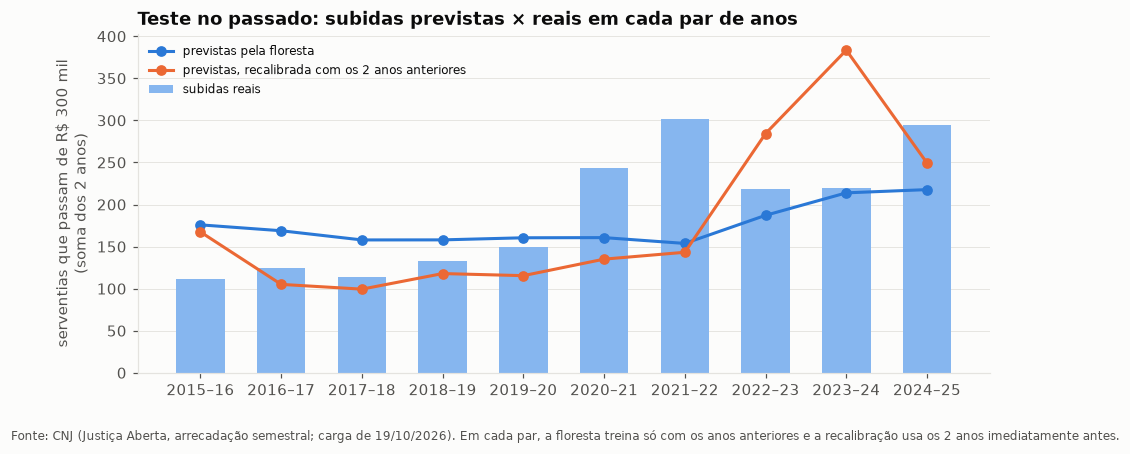

In [11]:
om1 = cl.origem_movel_subida(painel, range(2015, max(sc["anos_teste"])))
display(g.tabela(om1[["anos", "casos", "reais", "previstas_modelo", "previstas_recalibradas", "razao_modelo", "razao_recalibrada",
                      "brier_modelo", "brier_recalibrado"]],
                 {"casos": "int", "reais": "int", "previstas_modelo": "num1", "previstas_recalibradas": "num1",
                  "razao_modelo": "num2", "razao_recalibrada": "num2", "brier_modelo": "num3", "brier_recalibrado": "num3"}))
erro_abs = om1[["previstas_modelo", "previstas_recalibradas"]].sub(om1.reais, axis=0).abs().mean()
print(f"Erro absoluto médio da contagem nas {len(om1)} janelas: sem recalibração {g.num(erro_abs.iloc[0], 1)}; "
      f"recalibrada {g.num(erro_abs.iloc[1], 1)}. Janelas em que a recalibração melhorou o Brier: "
      f"{(om1.brier_recalibrado < om1.brier_modelo).sum()} de {len(om1)}.")

fig, ax = plt.subplots(figsize=(10, 4))
xo = np.arange(len(om1))
ax.bar(xo, om1.reais, color=g.AZUL["claro"], width=0.6, label="subidas reais")
ax.plot(xo, om1.previstas_modelo, marker="o", color=g.CORES[0], label="previstas pela floresta")
ax.plot(xo, om1.previstas_recalibradas, marker="o", color=g.CORES[1], label="previstas, recalibrada com os 2 anos anteriores")
ax.set_xticks(xo, [a[:5] + a[-2:] for a in om1.anos])
g.eixo_num(ax)
ax.set_ylabel(f"serventias que passam de {g.reais(limite, 0)}\n(soma dos 2 anos)")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Teste no passado: subidas previstas × reais em cada par de anos")
g.nota(fig, "Fonte: CNJ (Justiça Aberta, arrecadação semestral; carga de 19/10/2026). Em cada par, a floresta treina só com os anos "
            "anteriores e a recalibração usa os 2 anos imediatamente antes.")
g.salvar(fig, "05b_subida_origem_movel")
plt.show()

**Como ler.** As barras são as subidas reais de cada par de anos; as linhas, as previstas.

**O que encontramos.**
- Até 2019–20, a floresta **superestima** as subidas (prevê 160 a 175 quando houve 110 a 150) e a recalibração corrige bem.
- Em **2020–21 e 2021–22**, as subidas reais **dobram** (243 e 302): a inflação de 2021–22 empurrou muitos cartórios por cima de um limite fixo. Nenhuma versão previu isso.
- Logo depois, em **2022–23 e 2023–24**, a recalibração aprendeu com esses anos de pico e passou a **superestimar** (284 e 383 previstas, contra 219 e 220 reais).
- Na média das 10 janelas, a recalibração **erra mais** a contagem (68 contra 53 serventias) e melhora o Brier em só 4 das 10 janelas. Em 2024–25, o teste do plano, ela ajudou.

**O que significa.** A subida de classe depende do **crescimento nominal da arrecadação**, que muda de um ano para o outro com a inflação. O modelo acerta **quem** tende a subir, mas **quantos** depende de um fator que ele não vê. A recalibração com os dois anos anteriores corrige na direção do passado recente, o que ajuda quando a tendência continua e atrapalha quando ela vira. **Mantemos o método do plano** (floresta recalibrada) como estimativa central, porque o crescimento de 2025 e do 2026-1 continua alto (notebook 02; T2), mas a **faixa** precisa carregar esse erro: ela é montada com os erros desta tabela (seção b6).

## b5. O que mais pesa na subida

**O método.** Importância por permutação da floresta treinada até 2023, medida pelo **aumento do Brier** no teste 2024–25; e os pesos da logística ajustada no treino.

In [12]:
nomes_sub = {"log_m1": "log da receita no ano anterior", "log_m2": "log da receita 2 anos antes",
             "cresc": "crescimento no último ano", "dist_limite": "distância ao limite", "log_max1": "log do maior semestre",
             "cresc2": "crescimento no ano anterior a esse", "n_atribuicoes": "nº de atribuições", "log_pop": "log da população"}
grupos_sub = {nomes_sub.get(v, dados.NOMES_ATRIBUICOES.get(v, v)): [v] for v in cl.VARIAVEIS_SUBIDA}
imp_sub = cl.importancia_no_teste(floresta_t, x_te, y_te, grupos_sub, metrica="Brier")
coef_sub = cl.coeficientes_logistica(x_tr, y_tr)
coef_sub["variavel"] = [nomes_sub.get(v, dados.NOMES_ATRIBUICOES.get(v, v)) for v in coef_sub.variavel]
display(g.tabela(imp_sub.head(8), {"perda_media": "num3", "perda_dp": "num3"})
        .rename(columns={"perda_media": "aumento médio do Brier", "perda_dp": "desvio padrão"}))
print("Aumento do Brier com 4 casas (3 primeiras):", "; ".join(f"{v}: {g.num(p, 4)}" for v, p in zip(imp_sub.variavel[:3], imp_sub.perda_media[:3])))
display(g.tabela(coef_sub.head(8), {"peso": "num2", "razao_de_chances": "num2", "desvio_padrao": "num2"})
        .rename(columns={"razao_de_chances": "razão de chances (1 desvio a mais)", "desvio_padrao": "1 desvio padrão ="}))

,variavel,aumento médio do Brier,desvio padrão
0,log do maior semestre,"0,009","0,001"
1,distância ao limite,"0,004","0,000"
2,log da receita no ano anterior,"0,003","0,000"
3,log da receita 2 anos antes,"0,002","0,000"
4,Protesto,"0,000","0,000"
5,nº de atribuições,"0,000","0,000"
6,Registro de imóveis (RI),"0,000","0,000"
7,Pessoas jurídicas (RCPJ),"-0,000","0,000"


Aumento do Brier com 4 casas (3 primeiras): log do maior semestre: 0,0091; distância ao limite: 0,0035; log da receita no ano anterior: 0,0033


,variavel,peso,razão de chances (1 desvio a mais),1 desvio padrão =
0,log do maior semestre,"4,39","81,04","1,44"
1,distância ao limite,"-1,34","0,26","1,45"
2,log da receita no ano anterior,"1,34","3,81","1,45"
3,log da receita 2 anos antes,"1,28","3,59","1,47"
4,Pessoas jurídicas (RCPJ),"1,25","3,49","0,30"
5,Títulos e documentos (RTD),"-0,70","0,50","0,30"
6,Notas,"0,63","1,87","0,44"
7,nº de atribuições,"-0,56","0,57","0,56"


**O que encontramos.** O que mais pesa é **quão perto do limite** a serventia já está (a receita do ano anterior, a distância ao limite e o maior semestre: as três dizem quase a mesma coisa) e o **crescimento recente**. Atribuições e população pesam pouco. Na logística, as variáveis de receita aparecem com pesos grandes e de sinais opostos porque são quase cópias umas das outras (a distância ao limite é o log do limite menos o log da receita): aqui os pesos individuais não devem ser lidos um a um; a importância por permutação é a leitura mais segura. O mesmo vale para RCPJ e RTD (razões de chances de 3,5 e 0,5), que são quase sempre a mesma serventia (notebook 03).

**O que significa.** A subida é, quase toda, uma questão de **quem está logo abaixo do limite e crescendo**. As 106 providas a menos de 10% do limite (notebook 02) são o primeiro lugar onde olhar.

**Limitações.** As variáveis de receita quase iguais dividem a importância entre si, então cada uma, sozinha, parece pesar menos do que o conjunto pesa. A importância é medida em dois anos de teste.

## b6. Entrega: quantas serventias devem subir em 2026 e 2027

**A pergunta.** Quantas serventias abaixo do limite em 2025 devem passar dele em 2026, e até 2027?

**O método.**
- **2026:** os casos são as serventias com receita de 2025 até o limite; a floresta é treinada com todos os anos até 2025 e recalibrada com **2024–25** (os dois anos mais recentes, a mesma regra do teste, deslocada para o presente). A contagem esperada é a soma das probabilidades.
- **2027:** como ainda não há receita de 2026, usamos um modelo de **2 anos à frente** (variáveis de 2025 para prever 2027), com a mesma construção: validado do mesmo jeito (origem móvel, horizonte de 2 anos) e recalibrado com os anos-alvo 2024–25. A pergunta respondida é "quantas das que estavam abaixo em 2025 estarão acima em 2027" (subidas acumuladas de 2026 e 2027, menos quem subiu e voltou).
- **Faixa P10–P90:** a estimativa central multiplicada pelos percentis 10 e 90 da razão "reais ÷ previstas" das janelas da origem móvel (seção b4), como a faixa da arrecadação no T2. Mostramos também, para comparar, a faixa que considera só o acaso e o ajuste da recalibração (reamostragem): ela é bem mais estreita, porque não inclui a mudança de ritmo entre anos, que é o erro maior.
- **Recorte das providas:** as obrigadas são as providas, então separamos as serventias providas hoje (a situação pode mudar até lá).

In [13]:
anos_base = max(sc["anos_teste"])
n26 = cl.casos_subida(media, maximo, info, anos_base + 1, limite, 1, com_resposta=False)
r26 = cl.prever_subidas(painel, n26, 1)
painel2 = cl.painel_subida(media, maximo, info, range(sc["primeiro_ano"], anos_base + 1), limite, horizonte=2)
om2 = cl.origem_movel_subida(painel2, range(2016, anos_base), horizonte=2)
n27 = cl.casos_subida(media, maximo, info, anos_base + 2, limite, 2, com_resposta=False)
r27 = cl.prever_subidas(painel2, n27, 2)
situacao = sv.set_index("cns").situacao
linhas = []
for ano, h, casos, r, om in [(anos_base + 1, 1, n26, r26, om1), (anos_base + 2, 2, n27, r27, om2)]:
    prov = casos.cns.map(situacao).eq("provida").to_numpy()
    for recorte, msk in [("todas", np.ones(len(casos), bool)), ("providas hoje", prov)]:
        for modelo, p, razoes in [("floresta recalibrada (principal)", r["p_recal"], om.razao_recalibrada),
                                  ("floresta sem recalibração", r["p"], om.razao_modelo)]:
            lo, c, hi = cl.faixa_por_erros(p[msk].sum(), razoes)
            linhas.append({"ano": ano, "horizonte": h, "recorte": recorte, "abaixo_do_limite_no_ano_base": int(msk.sum()),
                           "p10": lo, "esperado": c, "p90": hi, "modelo": modelo,
                           "anos_recalibracao": "–".join(map(str, r["anos_cal"])) if "recalibrada" in modelo else "—"})
entrega = cl.tabela_subidas(linhas)
display(g.tabela(entrega, {"abaixo_do_limite_no_ano_base": "int", "p10": "num1", "esperado": "num1", "p90": "num1"}))
acaso = cl.faixa_contagem(r26["cal_p"], r26["cal_y"], r26["p"])
print(f"2026, só acaso + ajuste da recalibração (reamostragem): {g.num(acaso[0])} a {g.num(acaso[2])} (central {g.num(acaso[1], 1)}).")
print(f"Erro da contagem na origem móvel de 2 anos à frente: sem recalibração {g.num(om2.previstas_modelo.sub(om2.reais).abs().mean(), 1)}; "
      f"recalibrada {g.num(om2.previstas_recalibradas.sub(om2.reais).abs().mean(), 1)} ({len(om2)} janelas).")
display(g.tabela(om2[["anos", "reais", "previstas_modelo", "previstas_recalibradas", "razao_modelo", "razao_recalibrada"]],
                 {"reais": "int", "previstas_modelo": "num1", "previstas_recalibradas": "num1", "razao_modelo": "num2",
                  "razao_recalibrada": "num2"}))

,ano,horizonte,recorte,abaixo_do_limite_no_ano_base,p10,esperado,p90,modelo,anos_recalibracao
0,2026,1,todas,1.158,"95,6","144,9","265,1",floresta recalibrada (principal),2024–2025
1,2026,1,todas,1.158,"75,0","105,1","163,7",floresta sem recalibração,—
2,2026,1,providas hoje,524,"65,7","99,7","182,4",floresta recalibrada (principal),2024–2025
3,2026,1,providas hoje,524,"55,2","77,4","120,6",floresta sem recalibração,—
4,2027,2,todas,1.158,"152,8","210,2","468,3",floresta recalibrada (principal),2024–2025
5,2027,2,todas,1.158,"111,2","172,7","308,0",floresta sem recalibração,—
6,2027,2,providas hoje,524,"102,1","140,4","312,8",floresta recalibrada (principal),2024–2025
7,2027,2,providas hoje,524,"79,6","123,7","220,6",floresta sem recalibração,—


2026, só acaso + ajuste da recalibração (reamostragem): 133 a 160 (central 144,9).
Erro da contagem na origem móvel de 2 anos à frente: sem recalibração 108,6; recalibrada 122,5 (9 janelas).


,anos,reais,previstas_modelo,previstas_recalibradas,razao_modelo,razao_recalibrada
0,2016–2017,200,"316,8","290,6","0,63","0,69"
1,2017–2018,202,"312,2","245,6","0,65","0,82"
2,2018–2019,206,"284,2","167,6","0,72","1,23"
3,2019–2020,233,"279,1","169,6","0,83","1,37"
4,2020–2021,330,"276,9","174,1","1,19","1,89"
5,2021–2022,482,"270,6","194,2","1,78","2,48"
6,2022–2023,468,"260,9","216,3","1,79","2,16"
7,2023–2024,377,"303,8","363,7","1,24","1,04"
8,2024–2025,440,"358,3","597,4","1,23","0,74"


In [14]:
# conferência parcial: o 1º semestre de 2026 já saiu (incompleto: há serventias sem informar; notebook 01)
s1 = serie[(serie.ano == anos_base + 1) & (serie.semestre == 1)].set_index("cns")
v1 = n26.cns.map(s1.arrecadacao)
print(f"Das {g.num(len(n26))} serventias abaixo do limite em 2025, {g.num((v1 > limite).sum())} já passaram de "
      f"{g.reais(limite)} no 1º semestre de 2026; {g.num(n26.cns.map(s1.informado).eq(False).sum())} ainda não informaram.")

Das 1.158 serventias abaixo do limite em 2025, 97 já passaram de R$ 300,0 mil no 1º semestre de 2026; 34 ainda não informaram.


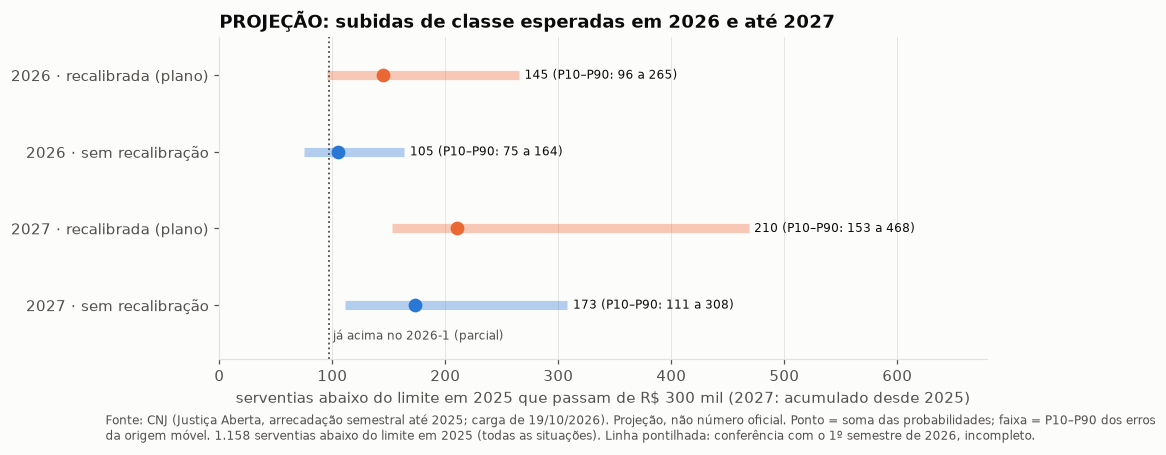

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
mostra = entrega[entrega.recorte == "todas"].reset_index(drop=True)
rot = [f"{a} · {'recalibrada (plano)' if 'principal' in m else 'sem recalibração'}" for a, m in zip(mostra.ano, mostra.modelo)]
yy = np.arange(len(mostra))[::-1]
for yv, (_, r), cor in zip(yy, mostra.iterrows(), [g.CORES[1], g.CORES[0]] * 2):
    ax.plot([r.p10, r.p90], [yv, yv], color=cor, linewidth=6, alpha=0.35, solid_capstyle="butt")
    ax.plot(r.esperado, yv, "o", color=cor, markersize=8)
    ax.text(r.p90 + 5, yv, f"{g.num(r.esperado)} (P10–P90: {g.num(r.p10)} a {g.num(r.p90)})", va="center", fontsize=8)
ax.axvline((v1 > limite).sum(), color=g.TEXTO_2, linestyle=":", linewidth=1.2)
ax.text((v1 > limite).sum(), -0.45, " já acima no 2026-1 (parcial)", fontsize=8, color=g.TEXTO_2)
ax.set_ylim(-0.7, len(mostra) - 0.5)
ax.set_yticks(yy, rot)
ax.set_xlim(0, mostra.p90.max() * 1.45)
ax.set_xlabel(f"serventias abaixo do limite em 2025 que passam de {g.reais(limite, 0)} (2027: acumulado desde 2025)")
ax.grid(axis="y", visible=False)
ax.set_title("PROJEÇÃO: subidas de classe esperadas em 2026 e até 2027")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta, arrecadação semestral até 2025; carga de 19/10/2026). Projeção, não número oficial. "
            f"Ponto = soma das probabilidades; faixa = P10–P90 dos erros\nda origem móvel. {g.num(len(n26))} serventias "
            f"abaixo do limite em 2025 (todas as situações). Linha pontilhada: conferência com o 1º semestre de 2026, incompleto.")
g.salvar(fig, "05b_subidas_projecao_2026_2027")
plt.show()

**Como ler.** Cada linha é uma projeção: o ponto é a contagem esperada e a barra, a faixa P10–P90. Em laranja, o método do plano (recalibrado); em azul, sem recalibração. A linha pontilhada é quantas serventias **já** passaram do limite só no 1º semestre de 2026 (com dado incompleto).

**O que encontramos.**
- **2026:** das **1.158** serventias abaixo do limite em 2025, devem passar dele **cerca de 145** (P10–P90: **96 a 265**), pelo método do plano. Sem a recalibração, 105 (75 a 164). Das **524 providas hoje** abaixo do limite, devem subir **cerca de 100**: é o acréscimo esperado ao universo de obrigadas em 2026, antes de descontar quem cai para a Classe 1 no sentido contrário.
- **Conferência:** só no 1º semestre de 2026, **97** dessas serventias já passaram de R$ 300 mil, e 34 ainda não informaram. Como o 2º semestre costuma arrecadar mais que o 1º (notebook 02), é razoável esperar pelo menos esse número no ano: a projeção central (145) é compatível; a faixa sem recalibração fica mais perto do piso.
- **Até 2027:** cerca de **210** das que estavam abaixo em 2025 devem estar acima em 2027 (P10–P90: **153 a 468**). A faixa é larga porque, 2 anos à frente, o erro de ritmo dobra de peso.
- A faixa que considera só o acaso e o ajuste (133 a 160 em 2026) é **enganosamente estreita**: o erro maior vem da mudança no ritmo de crescimento, não do sorteio.

**O que significa para o Prov. 227.** Com o limite fixo em R$ 300 mil, o universo de obrigadas deve **crescer** algo como 100 providas em 2026 (≈ +9% sobre as ≈ 1.121 de hoje), com faixa larga. Se o limite for corrigido pela inflação (art. 16, §2º, do Prov. 213), as subidas serão menores: esse cenário é do notebook 07, que usa esta tabela como insumo.

**Limitações.**
- **Projeção, não número oficial.** O universo oficial (≈ 1.121) não muda.
- A subida depende do crescimento nominal da arrecadação, que o modelo não prevê; a faixa vem de só 10 janelas (9 para 2 anos), sobrepostas, então seus percentis são aproximados.
- A recalibração com os dois anos anteriores **não** melhorou a contagem em média na origem móvel (seção b4). A escolha de mantê-la segue o plano e o ritmo alto de 2025–26; é uma questão para o autor (relatório da parte B).
- Só entram serventias com receita em 2024 e 2025 e abaixo do limite em 2025; as que estavam com receita zero ou sem declarar não entram.
- O modelo não sabe de mudanças de situação (vagas providas por concurso, ou o contrário) nem de saltos de declaração (notebook 01: 45 saltos de 10× ou mais em 2025).

### Desenho da tabela de subidas (insumo do notebook 07)

A entrega do 05b é a tabela acima, gerada pela função `classificacao.tabela_subidas` (com teste). O plano não pede uma tabela `gold.analise_*` para o 05; ela fica como insumo do notebook 07, que monta a `gold.analise_previsao`.

| Coluna | Tipo | O que é |
|---|---|---|
| `ano` | inteiro | ano projetado (2026, 2027) |
| `horizonte` | inteiro | anos à frente do último ano com dado (1 ou 2) |
| `recorte` | texto | `todas` ou `providas hoje` |
| `abaixo_do_limite_no_ano_base` | inteiro | serventias com receita até o limite em 2025 |
| `p10`, `esperado`, `p90` | decimal | contagem esperada de subidas e a faixa |
| `modelo` | texto | floresta recalibrada (principal) ou sem recalibração |
| `anos_recalibracao` | texto | anos usados na recalibração |

---
## Conclusões

1. **Vacância (associação, T4):** a floresta reconhece as vagas com **AUC 0,88** (logística 0,85; chute 0,50), batendo com o T4. As vagas são os **cartórios pequenos** de registro civil em lugares pequenos; sem a receita e o CLT (medidos sob o interino), a AUC ainda é de 0,82. O risco de vacância observado se concentra **fora** do universo, mas o modelo erra nas vagas grandes.
2. **Subida de classe (T3):** a floresta tem Brier **0,068** e AUC 0,88 em 2024–25, batendo com o T3, mas prevê **218 subidas contra 294** reais. A recalibração com 2022–23 leva a 249 (−15%).
3. **A recalibração não é uma correção garantida:** na origem móvel de 10 janelas, ela erra mais, em média, do que o modelo sem recalibrar, porque o ritmo das subidas muda com a inflação.
4. **Projeção (não oficial):** cerca de **145 subidas em 2026** (P10–P90: 96 a 265), **≈ 100 entre as providas**; cerca de **210 até 2027** (153 a 468). O 2026-1 parcial já tem 97 acima do limite. Insumo do notebook 07.